In [2]:
import pandas as pd
from pathlib import Path

# Define the file path
A_FILE = Path("../data/imodulondb/precise_mg1655-A.csv")

# Load the A matrix
A_df = pd.read_csv(A_FILE)

# Set iModulon names as row index
A_df = A_df.set_index("imodulon_name")

# Convert all activity values to numeric
A_df = A_df.apply(pd.to_numeric, errors="raise")

print("A matrix shape:", A_df.shape)
A_df.head()

A matrix shape: (115, 587)


,imodulon_k,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
imodulon_name,,,,,,,,,,,,,,,,,,,,,
Maltose,0,-2.055020,-7.854680,-3.801165,-8.910330,-8.774707,-9.808729,-9.839266,-9.722301,-9.514902,...,-3.768263,6.433405,6.485760,7.932573,6.350174,-7.524755,-7.395785,2.227343,2.052760,-3.713089
Crp,1,-0.743523,-14.563921,-1.883512,-26.365930,-27.221542,-17.491780,-16.242297,-18.973374,-20.933760,...,5.785161,14.018716,14.038371,13.042281,11.253342,-8.194162,-6.714543,5.041467,4.998130,-3.099815
UC-3,2,1.527342,-19.282351,-14.069122,-18.026647,-17.941710,-10.588645,-9.681105,-16.090947,-13.254534,...,-11.840739,-9.950526,-10.882700,-14.804355,-13.990962,-7.206556,-7.568958,-1.343946,-0.191752,-15.966480
Glycolate,3,3.936744,-3.013659,2.084086,3.622852,3.604913,1.208137,0.894482,4.325175,4.450917,...,-0.229852,9.235786,9.038167,10.998165,10.383810,-1.312373,-1.707038,6.918771,7.404890,2.282215
RpoS,4,-2.032111,20.322186,-0.686634,44.199040,43.869783,28.520332,27.791944,35.382644,35.594931,...,21.984066,8.563736,9.068640,24.440608,24.983238,20.590632,20.028142,6.270664,5.956805,-0.057726


In [3]:
# Keep the original A matrix unchanged
A_filtered = A_df.copy()

# Set activity values between -5 and +5 to zero
A_filtered = A_filtered.where(A_filtered.abs() > 5, 0)

# Count non-zero values before and after filtering
print("Original non-zero values:", (A_df != 0).sum().sum())
print("Filtered non-zero values:", (A_filtered != 0).sum().sum())

# Preview the filtered matrix
display(A_filtered.iloc[:5, :8])

Original non-zero values: 67504
Filtered non-zero values: 12976


,imodulon_k,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104
imodulon_name,,,,,,,,
Maltose,0,0.0,-7.854680,0.000000,-8.910330,-8.774707,-9.808729,-9.839266
Crp,0,0.0,-14.563921,0.000000,-26.365930,-27.221542,-17.491780,-16.242297
UC-3,0,0.0,-19.282351,-14.069122,-18.026647,-17.941710,-10.588645,-9.681105
Glycolate,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
RpoS,0,0.0,20.322186,0.000000,44.199040,43.869783,28.520332,27.791944


In [4]:
import pandas as pd
from pathlib import Path

# Load sample metadata
DATA_DIR = Path.cwd().parent / "data" / "imodulondb"
samples = pd.read_csv(
    DATA_DIR / "precise_mg1655-sample_table.csv"
)

# Select antibiotic exposure samples
antibiotic_meta = samples[
    samples["project_name"] == "AntibiotICA"
].copy()

# Select stationary phase samples
stationary_meta = samples[
    samples["project_name"] == "stationary-TRN"
].copy()

print("Antibiotic samples:", len(antibiotic_meta))
print("Stationary TRN samples:", len(stationary_meta))

print("\nAntibiotic conditions:")
print(antibiotic_meta["condition"].unique())

print("\nStationary TRN conditions:")
print(stationary_meta["condition"].unique())

Antibiotic samples: 30
Stationary TRN samples: 22

Antibiotic conditions:
['m9_ctrl' 'rpmi_ctrl' 'camhb_ctrl' 'm9_mero' 'rpmi_mero' 'camhb_mero'
 'm9_trisulf' 'rpmi_trisulf' 'camhb_trisulf' 'm9_cef' 'rpmi_cef'
 'camhb_cef' 'm9_cipro' 'rpmi_cipro' 'camhb_cipro']

Stationary TRN conditions:
['stationary_C_3h' 'stationary_N_3h' 'stationary_C_4h' 'stationary_N_4h'
 'stationary_S_4h' 'stationary_C_5h' 'stationary_N_5h' 'stationary_N_8h'
 'stationary_S_8h' 'stationary_N_12h' 'stationary_S_12h']


In [5]:
# Remove the iModulon ID column from the activity matrix
A_activity = A_df.drop(columns=["imodulon_k"])

# Define a function to select samples using metadata
def filter_A_by_metadata(metadata, A_matrix=A_activity):

    # Get sample IDs from metadata
    sample_ids = metadata["unique_identifier"].tolist()

    # Keep only samples present in the A matrix
    valid_ids = [
        sample_id for sample_id in sample_ids
        if sample_id in A_matrix.columns
    ]

    # Report samples missing from the A matrix
    missing_ids = set(sample_ids) - set(valid_ids)

    print("Requested samples:", len(sample_ids))
    print("Matched samples:", len(valid_ids))
    print("Missing samples:", len(missing_ids))

    # Return the selected activity matrix
    return A_matrix[valid_ids].copy()


# Extract the two experimental groups separately
print("\n--- Antibiotics ---")
A_antibiotic = filter_A_by_metadata(antibiotic_meta)

print("\n--- Stationary TRN ---")
A_stationary = filter_A_by_metadata(stationary_meta)

print("\nAntibiotic A matrix:", A_antibiotic.shape)
print("Stationary TRN A matrix:", A_stationary.shape)


--- Antibiotics ---
Requested samples: 30
Matched samples: 30
Missing samples: 0

--- Stationary TRN ---
Requested samples: 22
Matched samples: 22
Missing samples: 0

Antibiotic A matrix: (115, 30)
Stationary TRN A matrix: (115, 22)


PCA input shape: (30, 115)
Explained variance ratio: [0.63759046 0.16080775]


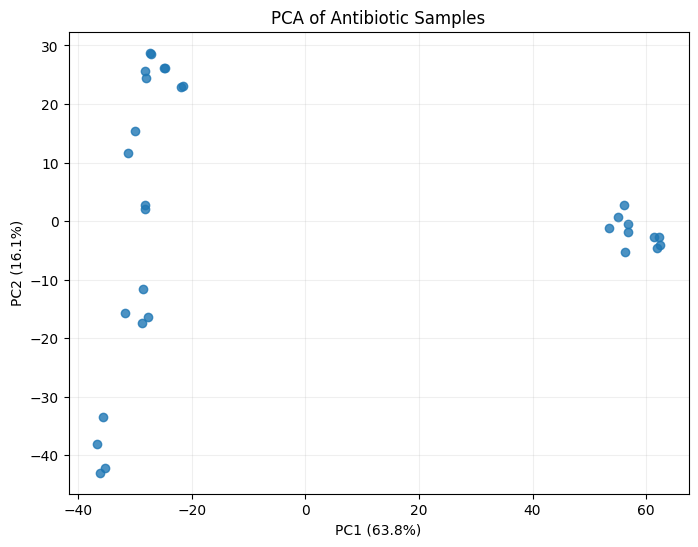

In [6]:
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

# Transpose: rows = samples, columns = iModulons
X_antibiotic = A_antibiotic.T

# Perform PCA using the original activity values
pca_antibiotic = PCA(n_components=2)
antibiotic_pcs = pca_antibiotic.fit_transform(X_antibiotic)

# Store PCA coordinates
antibiotic_pca_df = pd.DataFrame(
    antibiotic_pcs,
    index=X_antibiotic.index,
    columns=["PC1", "PC2"]
)

# Print explained variance
print("PCA input shape:", X_antibiotic.shape)
print(
    "Explained variance ratio:",
    pca_antibiotic.explained_variance_ratio_
)

# Plot PCA
plt.figure(figsize=(8, 6))

plt.scatter(
    antibiotic_pca_df["PC1"],
    antibiotic_pca_df["PC2"],
    alpha=0.8
)

plt.xlabel(
    f"PC1 ({pca_antibiotic.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"PC2 ({pca_antibiotic.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Antibiotic Samples")
plt.grid(alpha=0.2)
plt.show()

In [7]:
# Check available metadata columns
print("Metadata columns:")
print(antibiotic_meta.columns.tolist())

# Preview sample metadata
display(antibiotic_meta.head())

# Check PCA sample IDs
print("PCA sample IDs:")
print(antibiotic_pca_df.index[:5].tolist())

Metadata columns:
['unique_identifier', 'project_name', 'condition', 'replicate_id', 'reference_condition_identifier', 'reference_strain', 'deleted_genes', 'mutated_genes', 'overexpressed_genes', 'perturbed_gene_ids', 'doi', 'pmid', 'organism', 'dataset', 'R1', 'R2', 'pH', 'GEO', 'qc_id', 'project', 'Platform', 'run_date', 'full_name', 'sample_id', 'Base Media', 'Supplement', 'show_study', 'study_sort', 'Culture Type', 'LibraryLayout', 'passed_fastqc', 'Evolved Sample', 'PxK_sample_type', 'Temperature (C)', 'Additional Details', 'Strain Description', 'Carbon Source (g/L)', 'Biological Replicates', 'Nitrogen Source (g/L)', 'reference_condition_old', 'passed_global_correlation', 'passed_reads_mapped_to_CDS', 'passed_replicate_correlations', 'contact', 'creator', 'Growth_Phase', 'Electron Acceptor', 'Growth Rate (1/hr)', 'Sequencing Machine', 'Trace Element Mixture', 'Run', 'SRX', 'n_replicates', 'passed_pct_reads_mapped', 'passed_number_replicates', 'passed_similar_replicates', 'Antibiot

,unique_identifier,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,overexpressed_genes,perturbed_gene_ids,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
302,pmg_wt_371,AntibiotICA,m9_ctrl,1,pmg_wt_371;pmg_wt_372,MG1655,NaN,NaN,NaN,NaN,...,sauer trace element mixture,SRR12820309,SRX9288042,2.0,True,True,True,NaN,[object Object],[object Object]
303,pmg_wt_372,AntibiotICA,m9_ctrl,2,pmg_wt_371;pmg_wt_372,MG1655,NaN,NaN,NaN,NaN,...,sauer trace element mixture,SRR12820310,SRX9288043,2.0,True,True,True,NaN,[object Object],NaN
304,pmg_wt_373,AntibiotICA,rpmi_ctrl,1,pmg_wt_371;pmg_wt_372,MG1655,NaN,NaN,NaN,NaN,...,NaN,SRR12820311,SRX9288044,2.0,True,True,True,NaN,[object Object],NaN
305,pmg_wt_374,AntibiotICA,rpmi_ctrl,2,pmg_wt_371;pmg_wt_372,MG1655,NaN,NaN,NaN,NaN,...,NaN,SRR12820312,SRX9288045,2.0,True,True,True,NaN,[object Object],NaN
306,pmg_wt_375,AntibiotICA,camhb_ctrl,1,pmg_wt_371;pmg_wt_372,MG1655,NaN,NaN,NaN,NaN,...,NaN,SRR12820313,SRX9288046,2.0,False,True,True,NaN,[object Object],NaN


PCA sample IDs:
['pmg_wt_371', 'pmg_wt_372', 'pmg_wt_373', 'pmg_wt_374', 'pmg_wt_375']


medium
m9       10
rpmi     10
camhb    10
Name: count, dtype: int64


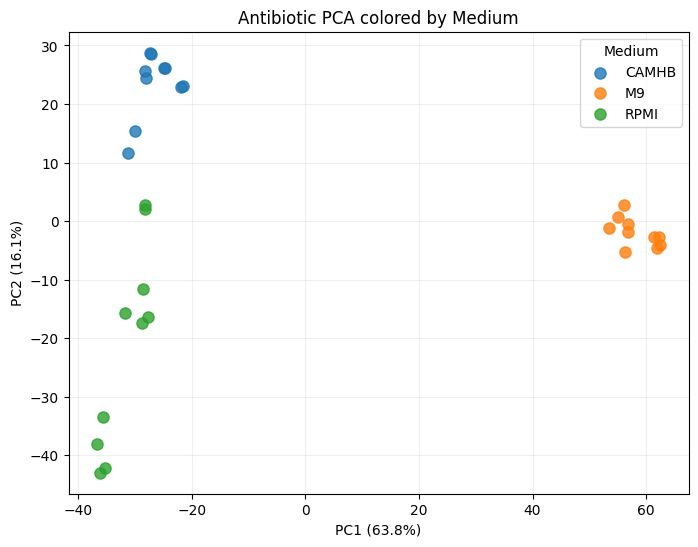

In [8]:
# Merge PCA coordinates with sample metadata
antibiotic_pca_meta = antibiotic_pca_df.merge(
    antibiotic_meta[
        ["unique_identifier", "condition", "Base Media", "replicate_id"]
    ],
    left_index=True,
    right_on="unique_identifier",
    how="left",
    validate="one_to_one"
)

# Extract medium from condition names
antibiotic_pca_meta["medium"] = (
    antibiotic_pca_meta["condition"]
    .str.split("_")
    .str[0]
    .str.lower()
)

# Check the number of samples in each medium
print(antibiotic_pca_meta["medium"].value_counts())

# Plot PCA colored by medium
plt.figure(figsize=(8, 6))

for medium, group in antibiotic_pca_meta.groupby("medium"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=medium.upper(),
        s=65,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({pca_antibiotic.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"PC2 ({pca_antibiotic.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("Antibiotic PCA colored by Medium")
plt.legend(title="Medium")
plt.grid(alpha=0.2)
plt.show()

antibiotic
ctrl       6
mero       6
trisulf    6
cef        6
cipro      6
Name: count, dtype: int64


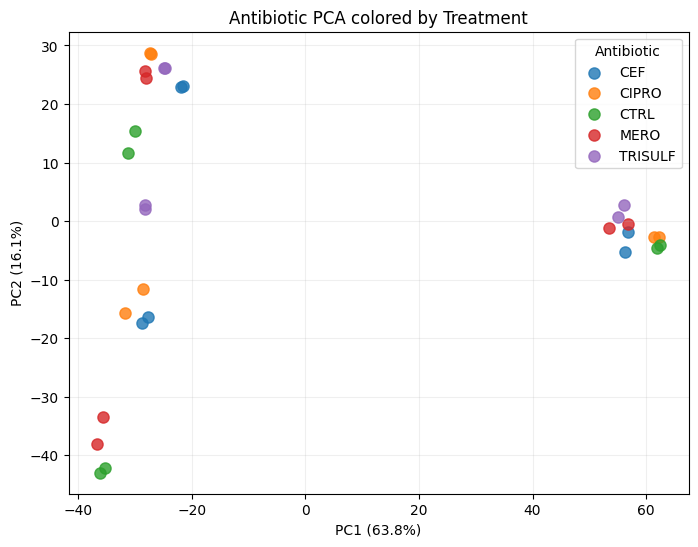

In [9]:
# Extract antibiotic treatment from condition names
antibiotic_pca_meta["antibiotic"] = (
    antibiotic_pca_meta["condition"]
    .str.split("_", n=1)
    .str[1]
    .str.lower()
)

# Check treatment categories
print(antibiotic_pca_meta["antibiotic"].value_counts())

# Plot PCA colored by antibiotic treatment
plt.figure(figsize=(8, 6))

for antibiotic, group in antibiotic_pca_meta.groupby("antibiotic"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=antibiotic.upper(),
        s=65,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({pca_antibiotic.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"PC2 ({pca_antibiotic.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("Antibiotic PCA colored by Treatment")
plt.legend(title="Antibiotic")
plt.grid(alpha=0.2)
plt.show()

M9 PCA input shape: (10, 115)
Explained variance ratio: [0.57972385 0.1923924 ]


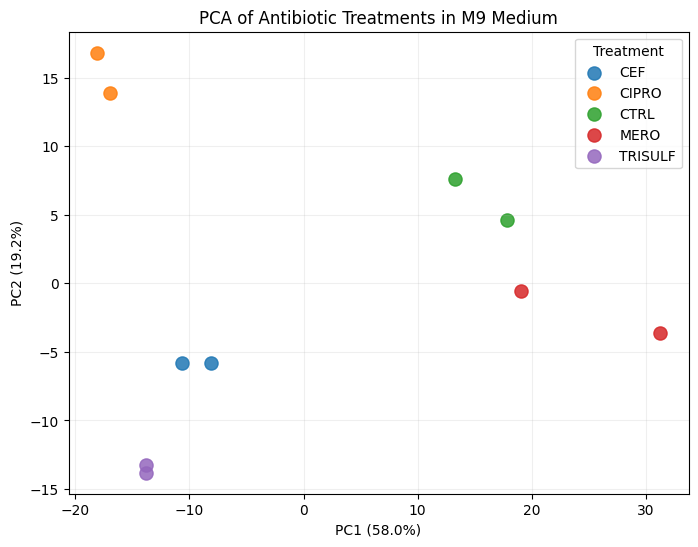

In [10]:
# Select M9 samples
m9_meta = antibiotic_pca_meta[
    antibiotic_pca_meta["medium"] == "m9"
].copy()

# Extract the corresponding activity profiles
X_m9 = X_antibiotic.loc[
    m9_meta["unique_identifier"]
].copy()

print("M9 PCA input shape:", X_m9.shape)

# Perform PCA on M9 samples only
pca_m9 = PCA(n_components=2)
m9_pcs = pca_m9.fit_transform(X_m9)

# Store PCA coordinates
m9_pca_df = pd.DataFrame(
    m9_pcs,
    index=X_m9.index,
    columns=["PC1", "PC2"]
)

# Add treatment and replicate information
m9_pca_df = m9_pca_df.merge(
    m9_meta[
        ["unique_identifier", "antibiotic", "replicate_id"]
    ],
    left_index=True,
    right_on="unique_identifier",
    how="left",
    validate="one_to_one"
)

print("Explained variance ratio:",
      pca_m9.explained_variance_ratio_)

# Plot PCA colored by antibiotic treatment
plt.figure(figsize=(8, 6))

for antibiotic, group in m9_pca_df.groupby("antibiotic"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=antibiotic.upper(),
        s=90,
        alpha=0.85
    )

plt.xlabel(
    f"PC1 ({pca_m9.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"PC2 ({pca_m9.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Antibiotic Treatments in M9 Medium")
plt.legend(title="Treatment")
plt.grid(alpha=0.2)
plt.show()

In [11]:
# Extract PCA loadings for each iModulon
loadings_m9 = pd.DataFrame(
    pca_m9.components_.T,
    index=X_m9.columns,
    columns=["PC1", "PC2"]
)

# Rank iModulons by their absolute contribution to PC1
top_pc1 = (
    loadings_m9
    .assign(abs_PC1=lambda df: df["PC1"].abs())
    .sort_values("abs_PC1", ascending=False)
    .head(10)
)

# Rank iModulons by their absolute contribution to PC2
top_pc2 = (
    loadings_m9
    .assign(abs_PC2=lambda df: df["PC2"].abs())
    .sort_values("abs_PC2", ascending=False)
    .head(10)
)

print("Top 10 iModulons contributing to PC1:")
display(top_pc1)

print("Top 10 iModulons contributing to PC2:")
display(top_pc2)

Top 10 iModulons contributing to PC1:


,PC1,PC2,abs_PC1
imodulon_name,,,
UC-9,0.351572,-0.033129,0.351572
FliA,-0.340528,-0.046206,0.340528
RcsAB,0.266411,-0.111227,0.266411
UC-4,0.250763,0.037042,0.250763
UC-5,-0.209140,0.165129,0.209140
LPS,0.209128,-0.101301,0.209128
Biofilm,0.199812,0.136116,0.199812
DNA Damage,-0.184750,0.446368,0.184750
Leucine_Dipeptide,-0.170265,-0.103900,0.170265


Top 10 iModulons contributing to PC2:


,PC1,PC2,abs_PC2
imodulon_name,,,
DNA Damage,-0.184750,0.446368,0.446368
RpoS,0.056327,0.281504,0.281504
Cysteine,0.104081,0.264582,0.264582
Pyrimidine,0.158240,0.245847,0.245847
Arginine,0.147480,0.241589,0.241589
Putrescine,-0.167631,-0.238655,0.238655
FlhDC-2,-0.123709,0.212740,0.212740
Methionine,0.091374,0.200338,0.200338
Lrp-2,-0.062202,-0.178488,0.178488


In [12]:
import pandas as pd
from pathlib import Path

# Path to iModulonDB data
IMODULON_DIR = Path("../data/imodulondb")

# Load iModulon annotation table
im_info = pd.read_csv(
    IMODULON_DIR / "precise_mg1655-im_table.csv"
)

print("Shape:", im_info.shape)
print("\nColumns:")
print(im_info.columns.tolist())

display(im_info.head())

Shape: (115, 14)

Columns:
['k', 'name', 'imodulon_name', 'regulator', 'function_description', 'category', 'explained_variance', 'exp_var', 'precision', 'recall', 'f1_score', 'num_genes', 'n_genes', 'n_conditions']


,k,name,imodulon_name,regulator,function_description,category,explained_variance,exp_var,precision,recall,f1_score,num_genes,n_genes,n_conditions
0,0,Maltose,Maltose,MalT,maltose transport and catabolism,carbon metabolism,0.006331,0.006331,0.800000,1.000000,0.888889,10,10,0
1,1,Crp,Crp,"Crp, RpoD",carbohydrate transport and metabolism,carbon metabolism,0.018146,0.018146,0.562500,0.076923,0.135338,32,32,0
2,2,UC-3,UC-3,NaN,unknown,unknown,0.026604,0.026604,NaN,NaN,0.000000,7,7,0
3,3,Glycolate,Glycolate,"RpoD, IHF, ArcA, PdhR, GlcC",glycolate/glyoxylate transport and metabolism,carbon metabolism,0.002824,0.002824,1.000000,1.000000,1.000000,6,6,0
4,4,RpoS,RpoS,RpoS,master regulator of global stress response,global stress,0.079112,0.079112,0.305085,0.155172,0.205714,118,118,0


In [13]:
# Select biological annotation columns
annotation_cols = [
    "imodulon_name",
    "regulator",
    "function_description",
    "category"
]

annotations = im_info[annotation_cols].copy()

# Match Top 10 PC1 iModulons with biological annotations
top_pc1_annotated = (
    top_pc1
    .reset_index()
    .merge(
        annotations,
        on="imodulon_name",
        how="left"
    )
)

# Match Top 10 PC2 iModulons with biological annotations
top_pc2_annotated = (
    top_pc2
    .reset_index()
    .merge(
        annotations,
        on="imodulon_name",
        how="left"
    )
)

# Display annotated PC1 results
print("Top 10 PC1 iModulons with biological functions:")
display(
    top_pc1_annotated[
        [
            "imodulon_name",
            "PC1",
            "regulator",
            "function_description",
            "category"
        ]
    ]
)

# Display annotated PC2 results
print("Top 10 PC2 iModulons with biological functions:")
display(
    top_pc2_annotated[
        [
            "imodulon_name",
            "PC2",
            "regulator",
            "function_description",
            "category"
        ]
    ]
)
# PC1: 
# MERO and CEF are both beta-lactam antibiotics targeting cell wall synthesis, 
# but they are separated along PC1.
# This suggests that different beta-lactam treatments may induce 
# distinct regulatory responses involving envelope stress and flagellar motility.


# PC2: 
# a large separation of Ciprofloxacin-treated samples, 
# exhibiting a distinct DNA damage-associated response. 
# This aligns with the known mechanism of action of Ciprofloxacin, 
# which targets DNA gyrase and topoisomerase IV, leading to DNA damage 
# and activation of the SOS response in bacteria.

Top 10 PC1 iModulons with biological functions:


,imodulon_name,PC1,regulator,function_description,category
0,UC-9,0.351572,NaN,unknown,unknown
1,FliA,-0.340528,FliA,flagellum biosynthesis and export/ motility,extracellular structures
2,RcsAB,0.266411,"RcsAB, RpoD",envelopse stress response,envelope stress
3,UC-4,0.250763,NaN,unknown,unknown
4,UC-5,-0.209140,"ArcA, IHF, Fis, Fnr",unknown,unknown
5,LPS,0.209128,NaN,lipopolysaccharide biosynthesis and export,extracellular structures
6,Biofilm,0.199812,"RpoS, ppGpp, BluR, MarA","biofilm formation, acid resistance, cold shock...",extracellular structures
7,DNA Damage,-0.184750,LexA,SOS response to DNA damage,DNA damage
8,Leucine_Dipeptide,-0.170265,"LeuO, Leu-tRNA",leucine biosynthesis/dipeptide transport,amino acid metabolism
9,Histidine,-0.168916,"RpoD, DksA, His-tRNA",histidine biosynthesis,amino acid metabolism


Top 10 PC2 iModulons with biological functions:


,imodulon_name,PC2,regulator,function_description,category
0,DNA Damage,0.446368,LexA,SOS response to DNA damage,DNA damage
1,RpoS,0.281504,RpoS,master regulator of global stress response,global stress
2,Cysteine,0.264582,CysB,"cysteine biosynthesis, sulfate assimilation",amino acid metabolism
3,Pyrimidine,0.245847,"PepA, UTP",pyrimidine transport and biosynthesis,nucleotide metabolism
4,Arginine,0.241589,ArgR,arginine transport and biosynthesis,amino acid metabolism
5,Putrescine,-0.238655,PuuR,putrescine transport and catabolism,nitrogen metabolism
6,FlhDC-2,0.212740,FlhDC,flagellum biosynthesis and export,extracellular structures
7,Methionine,0.200338,MetJ,methionine transport and biosynthesis,amino acid metabolism
8,Lrp-2,-0.178488,Lrp,global regulation of amino acid biosynthesis/c...,amino acid metabolism
9,UC-5,0.165129,"ArcA, IHF, Fis, Fnr",unknown,unknown


In [14]:
# Load iModulon gene weight matrix
M_df = pd.read_csv(
    IMODULON_DIR / "precise_mg1655-M.csv",
    index_col=0
)

print("M matrix shape:", M_df.shape)
print("First columns:", M_df.columns[:10].tolist())
print("First genes:", M_df.index[:10].tolist())

# Check whether target iModulons are present
target_imodulons = ["RcsAB", "FliA", "FlhDC-2"]

for name in target_imodulons:
    print(name, ":", name in M_df.columns)
display(M_df.iloc[:5, :5])

# Load iModulon membership thresholds
M_thresholds = pd.read_csv(
    IMODULON_DIR / "precise_mg1655-M_thresholds.csv"
)

print("Shape:", M_thresholds.shape)
print("Columns:", M_thresholds.columns.tolist())
display(M_thresholds.head())

M matrix shape: (4305, 115)
First columns: ['Maltose', 'Crp', 'UC-3', 'Glycolate', 'RpoS', 'SG_1', 'SG_2', 'Translation', 'Fnr-2', 'DNA Damage']
First genes: ['b0001', 'b0002', 'b0003', 'b0004', 'b0005', 'b0006', 'b0007', 'b0008', 'b0009', 'b0010']
RcsAB : True
FliA : True
FlhDC-2 : True


,Maltose,Crp,UC-3,Glycolate,RpoS
gene_id,,,,,
b0001,-0.000870,-0.000054,-0.003445,-0.014684,-0.011696
b0002,-0.010768,0.023009,-0.007085,0.007674,-0.006408
b0003,-0.013951,0.015926,-0.013038,0.001975,-0.005165
b0004,-0.013104,0.018371,-0.004472,0.005184,-0.002603
b0005,-0.009831,0.008026,0.013255,-0.007159,-0.002665


Shape: (115, 3)
Columns: ['imodulon_k', 'imodulon_name', 'threshold']


,imodulon_k,imodulon_name,threshold
0,0,Maltose,0.081560
1,1,Crp,0.068750
2,2,UC-3,0.070000
3,3,Glycolate,0.122903
4,4,RpoS,0.041741


In [15]:
# Target iModulons
target_imodulons = ["RcsAB", "FliA", "FlhDC-2"]

# Create a threshold lookup table
threshold_dict = M_thresholds.set_index(
    "imodulon_name"
)["threshold"]

# Extract member genes for each iModulon
imodulon_genes = {}

for imodulon in target_imodulons:

    # Get the corresponding membership threshold
    threshold = threshold_dict.loc[imodulon]

    # Select genes with absolute weights above the threshold
    members = M_df.loc[
        M_df[imodulon].abs() > threshold,
        imodulon
    ]

    # Store the selected gene IDs
    imodulon_genes[imodulon] = members.index.tolist()

    print(f"{imodulon}")
    print(f"Threshold: {threshold:.4f}")
    print(f"Number of member genes: {len(members)}")
    print(f"First 10 genes: {members.index[:10].tolist()}")
    print("-" * 50)

RcsAB
Threshold: 0.0687
Number of member genes: 29
First 10 genes: ['b0379', 'b1110', 'b1283', 'b1951', 'b2028', 'b2044', 'b2045', 'b2046', 'b2047', 'b2048']
--------------------------------------------------
FliA
Threshold: 0.0631
Number of member genes: 31
First 10 genes: ['b0763', 'b1070', 'b1071', 'b1082', 'b1083', 'b1194', 'b1421', 'b1566', 'b1742', 'b1760']
--------------------------------------------------
FlhDC-2
Threshold: 0.0477
Number of member genes: 36
First 10 genes: ['b1043', 'b1044', 'b1072', 'b1073', 'b1074', 'b1075', 'b1076', 'b1077', 'b1078', 'b1079']
--------------------------------------------------


In [16]:
# Load gene expression matrix
log_tpm = pd.read_csv(
    IMODULON_DIR / "precise_mg1655-log_tpm.csv",
    index_col=0
)

print("Expression matrix shape:", log_tpm.shape)
print("First genes:", log_tpm.index[:5].tolist())
print("First samples:", log_tpm.columns[:5].tolist())

# Check overlap between expression data and M9 samples
m9_sample_ids = m9_meta["unique_identifier"].tolist()

matched_samples = [
    sample for sample in m9_sample_ids
    if sample in log_tpm.columns
]

print("M9 samples matched:", len(matched_samples), "/", len(m9_sample_ids))

# Check how many member genes are available
for imodulon, genes in imodulon_genes.items():
    matched_genes = set(genes) & set(log_tpm.index)
    print(f"{imodulon}: {len(matched_genes)}/{len(genes)} genes matched")

Expression matrix shape: (4305, 586)
First genes: ['b0001', 'b0002', 'b0003', 'b0004', 'b0005']
First samples: ['pmg_wt_1', 'pmg_wt_10', 'pmg_wt_100', 'pmg_wt_101', 'pmg_wt_102']
M9 samples matched: 10 / 10
RcsAB: 29/29 genes matched
FliA: 31/31 genes matched
FlhDC-2: 36/36 genes matched


Δlog(TPM) = logTPM_treatment - logTPM_CTRL

In [17]:
# Select M9 samples from three treatments
selected_meta = m9_meta[
    m9_meta["antibiotic"].isin(["ctrl", "mero", "cef"])
].copy()

# Calculate mean gene expression for each treatment
mean_expression = {}

for treatment in ["ctrl", "mero", "cef"]:
    sample_ids = selected_meta.loc[
        selected_meta["antibiotic"] == treatment,
        "unique_identifier"
    ].tolist()

    mean_expression[treatment] = log_tpm[sample_ids].mean(axis=1)

mean_expression = pd.DataFrame(mean_expression)

# Calculate expression changes relative to control
expression_change = pd.DataFrame({
    "MERO_vs_CTRL": mean_expression["mero"] - mean_expression["ctrl"],
    "CEF_vs_CTRL": mean_expression["cef"] - mean_expression["ctrl"]
})

# Display expression changes for each iModulon
for imodulon in ["RcsAB", "FliA", "FlhDC-2"]:
    print(f"\n{imodulon} gene expression changes:")

    display(
        expression_change.loc[
            imodulon_genes[imodulon]
        ].head(10).round(3)
    )


RcsAB gene expression changes:


,MERO_vs_CTRL,CEF_vs_CTRL
gene_id,,
b0379,2.513,-0.408
b1110,1.539,-0.235
b1283,1.182,-0.475
b1951,1.585,-1.596
b2028,1.104,-0.488
b2044,-0.276,0.133
b2045,0.007,0.376
b2046,0.610,0.085
b2047,0.857,0.023



FliA gene expression changes:


,MERO_vs_CTRL,CEF_vs_CTRL
gene_id,,
b0763,-0.107,0.762
b1070,0.068,1.222
b1071,0.057,1.119
b1082,-0.348,2.177
b1083,-0.116,1.765
b1194,-0.517,1.892
b1421,-0.241,0.623
b1566,-0.316,1.237
b1742,0.225,1.601



FlhDC-2 gene expression changes:


,MERO_vs_CTRL,CEF_vs_CTRL
gene_id,,
b1043,0.075,-0.496
b1044,0.125,-0.133
b1072,-0.332,0.027
b1073,-0.493,0.073
b1074,-0.424,0.014
b1075,-0.441,0.353
b1076,-0.662,0.704
b1077,-0.521,0.819
b1078,-0.664,0.911


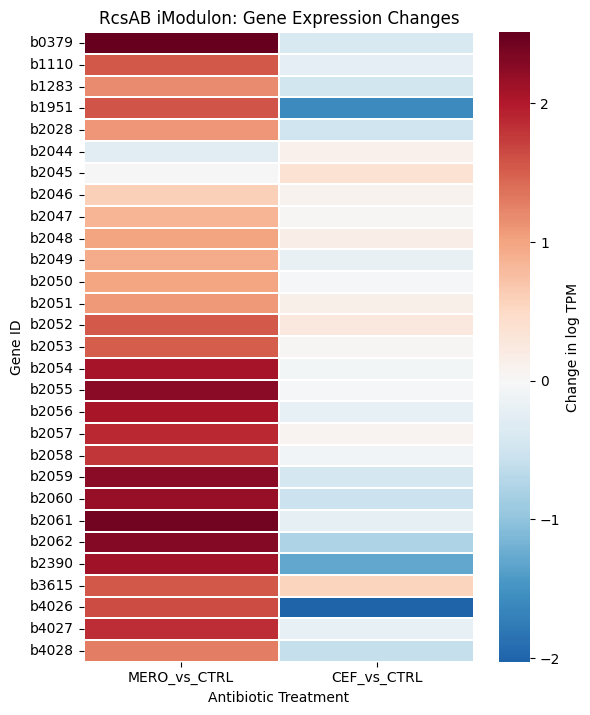

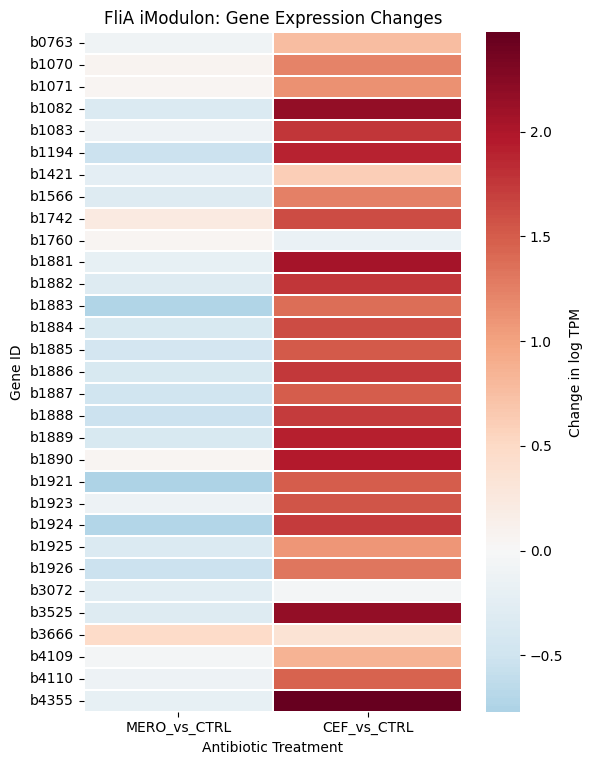

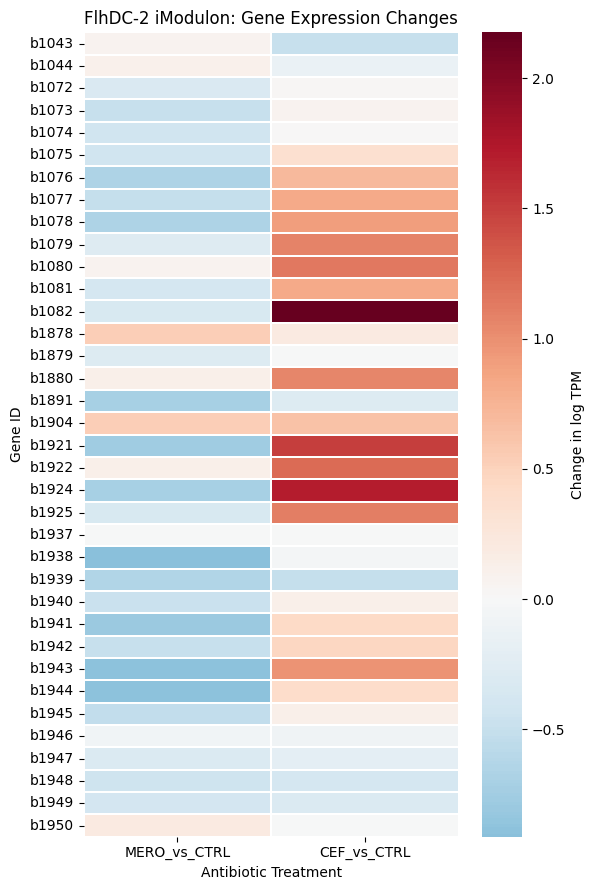

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot expression changes for all member genes
for imodulon in ["RcsAB", "FliA", "FlhDC-2"]:

    genes = imodulon_genes[imodulon]

    # Extract expression changes for member genes
    heatmap_data = expression_change.loc[
        genes,
        ["MERO_vs_CTRL", "CEF_vs_CTRL"]
    ]

    plt.figure(figsize=(6, max(6, len(genes) * 0.25)))

    sns.heatmap(
        heatmap_data,
        cmap="RdBu_r",
        center=0,
        annot=False,
        linewidths=0.3,
        cbar_kws={"label": "Change in log TPM"}
    )

    plt.title(f"{imodulon} iModulon: Gene Expression Changes")
    plt.xlabel("Antibiotic Treatment")
    plt.ylabel("Gene ID")
    plt.tight_layout()
    plt.show()
    # MERO and CEF show contrasting transcriptional responses


In [19]:
# Select stationary-TRN samples
stationary_meta = samples.loc[
    samples["project_name"] == "stationary-TRN"
].copy()

# Check sample metadata
print("Number of samples:", len(stationary_meta))

display(
    stationary_meta[
        ["unique_identifier", "condition", "replicate_id"]
    ].sort_values("condition")
)

# Count samples for each condition
print("\nSamples per condition:")
display(
    stationary_meta["condition"].value_counts()
)

Number of samples: 22


,unique_identifier,condition,replicate_id
277,pmg_wt_349,stationary_C_3h,1
279,pmg_wt_350,stationary_C_3h,2
283,pmg_wt_354,stationary_C_4h,2
282,pmg_wt_353,stationary_C_4h,1
290,pmg_wt_360,stationary_C_5h,2
288,pmg_wt_359,stationary_C_5h,1
297,pmg_wt_367,stationary_N_12h,1
298,pmg_wt_368,stationary_N_12h,2
280,pmg_wt_351,stationary_N_3h,1
281,pmg_wt_352,stationary_N_3h,2



Samples per condition:


condition
stationary_C_3h     2
stationary_N_3h     2
stationary_C_4h     2
stationary_N_4h     2
stationary_S_4h     2
stationary_C_5h     2
stationary_N_5h     2
stationary_N_8h     2
stationary_S_8h     2
stationary_N_12h    2
stationary_S_12h    2
Name: count, dtype: int64

Stationary PCA input shape: (22, 115)
Explained variance ratio: [0.37418765 0.31434948]


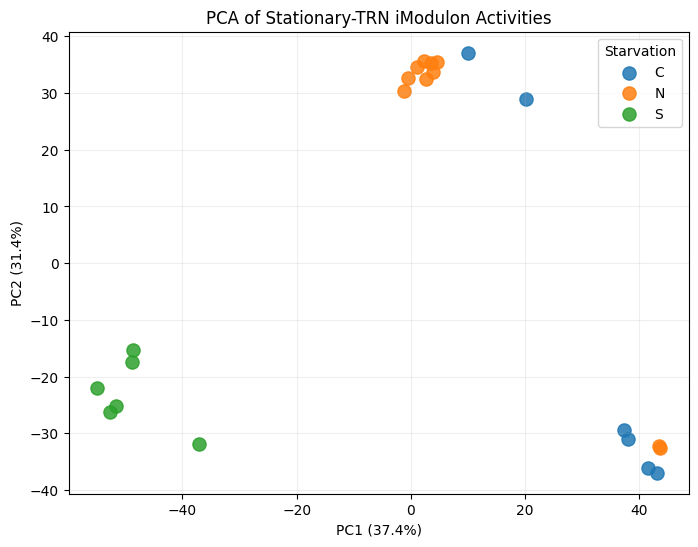

In [20]:
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

# Extract starvation type and time point
stationary_meta["starvation"] = (
    stationary_meta["condition"]
    .str.extract(r"stationary_([CNS])_")
)

stationary_meta["time_h"] = (
    stationary_meta["condition"]
    .str.extract(r"_(\d+)h$")[0]
    .astype(int)
)

# Select stationary-TRN samples from the A matrix
stationary_ids = stationary_meta["unique_identifier"].tolist()

X_stationary = A_df[stationary_ids].T.copy()

print("Stationary PCA input shape:", X_stationary.shape)

# Perform PCA on raw iModulon activities
pca_stationary = PCA(n_components=2)
stationary_pcs = pca_stationary.fit_transform(X_stationary)

# Create PCA results table
stationary_pca_df = pd.DataFrame(
    stationary_pcs,
    index=X_stationary.index,
    columns=["PC1", "PC2"]
)

stationary_pca_df = stationary_pca_df.join(
    stationary_meta.set_index("unique_identifier")[
        ["starvation", "time_h", "replicate_id"]
    ]
)

print("Explained variance ratio:",
      pca_stationary.explained_variance_ratio_)

# Plot PCA colored by starvation type
plt.figure(figsize=(8, 6))

for starvation, group in stationary_pca_df.groupby("starvation"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=starvation,
        s=90,
        alpha=0.85
    )

plt.xlabel(f"PC1 ({pca_stationary.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca_stationary.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of Stationary-TRN iModulon Activities")
plt.legend(title="Starvation")
plt.grid(alpha=0.2)
plt.show()

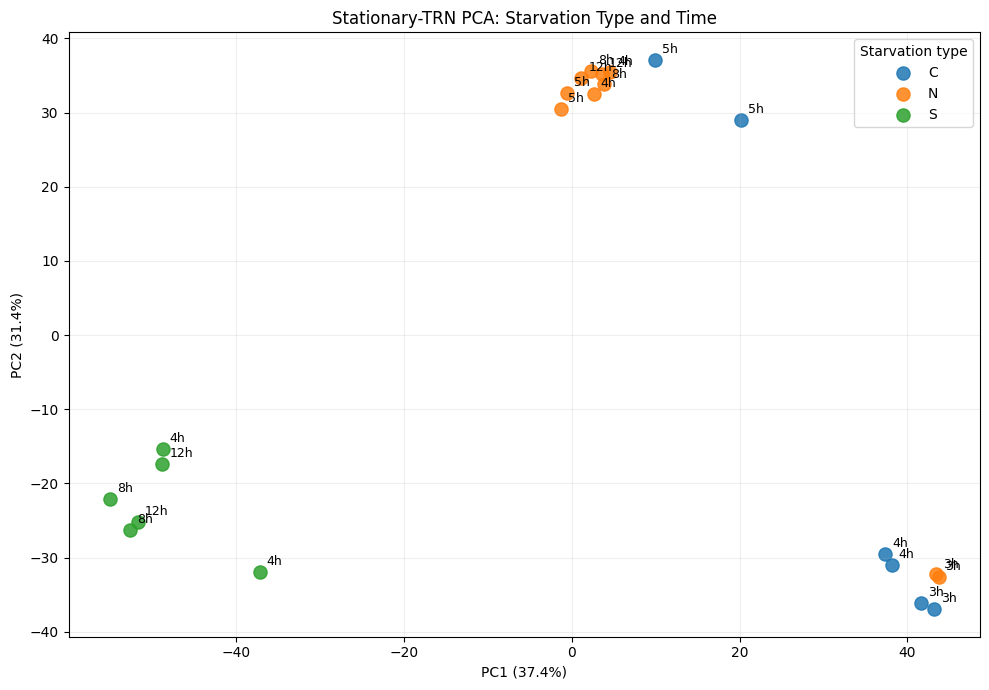

In [21]:
# Plot PCA with starvation colors and time labels
plt.figure(figsize=(10, 7))

colors = {
    "C": "tab:blue",
    "N": "tab:orange",
    "S": "tab:green"
}

for starvation, group in stationary_pca_df.groupby("starvation"):

    plt.scatter(
        group["PC1"],
        group["PC2"],
        color=colors[starvation],
        label=starvation,
        s=90,
        alpha=0.85
    )

    # Add time labels to individual samples
    for _, row in group.iterrows():
        plt.annotate(
            f'{row["time_h"]}h',
            (row["PC1"], row["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

plt.xlabel(
    f"PC1 ({pca_stationary.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"PC2 ({pca_stationary.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("Stationary-TRN PCA: Starvation Type and Time")
plt.legend(title="Starvation type")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [22]:
# Extract PCA loadings for stationary-TRN
loadings_stationary = pd.DataFrame(
    pca_stationary.components_.T,
    index=X_stationary.columns,
    columns=["PC1", "PC2"]
)

# Select biological annotations
annotations = im_info[
    ["imodulon_name", "regulator", "function_description", "category"]
].copy()

# Extract Top 10 iModulons for each principal component
for pc in ["PC1", "PC2"]:

    top_imodulons = (
        loadings_stationary
        .assign(abs_loading=lambda df: df[pc].abs())
        .sort_values("abs_loading", ascending=False)
        .head(10)
        .reset_index()
        .rename(columns={"index": "imodulon_name"})
    )

    # Merge PCA loadings with biological annotations
    top_annotated = top_imodulons.merge(
        annotations,
        on="imodulon_name",
        how="left"
    )

    print(f"\nTop 10 iModulons contributing to {pc}:")

    display(
        top_annotated[
            [
                "imodulon_name",
                pc,
                "regulator",
                "function_description",
                "category"
            ]
        ]
    )


# PC1: s-starved samples are strongly separated from c- and n-starved samples along PC1. 
# Sulfate iModulon is associated with S uptake and is regulated by CysB and Cb1. 
# Under sulfur limitation, bacteria may increase the expression of sulfur transport 
# and assimilation genes to compensate for reduced sulfur availability.
#



Top 10 iModulons contributing to PC1:


,imodulon_name,PC1,regulator,function_description,category
0,UC-5,0.497159,"ArcA, IHF, Fis, Fnr",unknown,unknown
1,Sulfate,-0.313824,"Cbl, CysB",cysteine transport and biosynthesis; aliphatic...,amino acid metabolism
2,GadX,0.227302,"GadX, RpoS",glutamate-dependent acid resistance system; mu...,envelope stress
3,Biofilm,-0.223035,"RpoS, ppGpp, BluR, MarA","biofilm formation, acid resistance, cold shock...",extracellular structures
4,Crp,0.220380,"Crp, RpoD",carbohydrate transport and metabolism,carbon metabolism
5,Purine,0.196496,"PurR, ppGpp",purine transport and biosynthesis,nucleotide metabolism
6,Pyrimidine,0.186396,"PepA, UTP",pyrimidine transport and biosynthesis,nucleotide metabolism
7,Leucine_Dipeptide,0.182200,"LeuO, Leu-tRNA",leucine biosynthesis/dipeptide transport,amino acid metabolism
8,Fnr-1,0.179394,Fnr,transition from aerobic to anaerobic growth,energy metabolism
9,ArcA-1,-0.152296,ArcA,anaerobiosis/repression of aerobic growth gene...,energy metabolism



Top 10 iModulons contributing to PC2:


,imodulon_name,PC2,regulator,function_description,category
0,NtrC-1,0.463285,NtrC,"nitrogen assimilation, ammonium transport",nitrogen metabolism
1,UC-3,-0.327553,NaN,unknown,unknown
2,NtrC-2,0.278092,"NtrC, RpoN","nitrogen assimilation, ammonium transport",nitrogen metabolism
3,RpoH,0.250439,RpoH,global heat shock response during log-phase; r...,temperature shock
4,Translation,-0.220380,RpsH,ribosome biogenesis,translation
5,ArcA-1,0.212370,ArcA,anaerobiosis/repression of aerobic growth gene...,energy metabolism
6,LPS,-0.185360,NaN,lipopolysaccharide biosynthesis and export,extracellular structures
7,Methionine,-0.182167,MetJ,methionine transport and biosynthesis,amino acid metabolism
8,Cysteine,-0.161336,CysB,"cysteine biosynthesis, sulfate assimilation",amino acid metabolism
9,Glutarate,0.160525,"GlaR, Crp, Lrp, RpoS, ppGpp, H-NS",glutarate/aminobutyrate transport and catabolism,amino acid metabolism


In [ ]:
# Compare Sulfate iModulon activity across starvation conditions
sulfate_activity = A_df.loc[
    "Sulfate",
    stationary_meta["unique_identifier"]
]

sulfate_results = stationary_meta[
    ["unique_identifier", "starvation", "time_h"]
].copy()

sulfate_results["Sulfate_activity"] = (
    sulfate_results["unique_identifier"]
    .map(sulfate_activity)
)

display(
    sulfate_results
    .groupby(["starvation", "time_h"])["Sulfate_activity"]
    .mean()
    .round(2)
)
# This is consistent with CysB/Cbl-associated regulation
# of sulfur uptake and assimilation pathways, potentially
# helping E. coli adapt to limited sulfur availability.

starvation  time_h
C           3          0.00
            4          4.23
            5          4.95
N           3          0.50
            4          3.52
            5          3.23
            8          4.33
            12         3.81
S           4         31.77
            8         29.22
            12        26.68
Name: Sulfate_activity, dtype: float64

In [ ]:
# Find ROS-related samples in the metadata
ros_mask = (
    samples["project_name"].astype(str).str.contains(
        "ROS|oxidative", case=False, na=False
    )
    |
    samples["condition"].astype(str).str.contains(
        "ROS|oxidative", case=False, na=False
    )
)

ros_meta = samples.loc[ros_mask].copy()

print("Number of matched samples:", len(ros_meta))

print("\nProject names:")
print(ros_meta["project_name"].value_counts())

print("\nConditions:")
print(ros_meta["condition"].value_counts())

display(
    ros_meta[
        ["unique_identifier", "project_name", "condition", "replicate_id"]
    ]
)
# wrong searching due to ros, ignore it. 
# wt_pq: wild-type + paraquat

Number of matched samples: 4

Project names:
project_name
single_nutrient_perturbation    2
Oxidative                       2
Name: count, dtype: int64

Conditions:
condition
Supp_Tyrosine_(10mM)    2
wt_pq                   2
Name: count, dtype: int64


,unique_identifier,project_name,condition,replicate_id
162,pmg_wt_245,single_nutrient_perturbation,Supp_Tyrosine_(10mM),1
163,pmg_wt_246,single_nutrient_perturbation,Supp_Tyrosine_(10mM),2
483,pmg_wt_534,Oxidative,wt_pq,1
484,pmg_wt_535,Oxidative,wt_pq,2


In [28]:
# Define control and paraquat-treated sample IDs
control_ids = ["pmg_wt_445", "pmg_wt_446"]
ros_ids = ["pmg_wt_534", "pmg_wt_535"]

ros_sample_ids = control_ids + ros_ids

# Combine sample metadata
ros_meta = samples[
    samples["unique_identifier"].isin(ros_sample_ids)
].copy()

# Label the two experimental groups
ros_meta["treatment"] = ros_meta["unique_identifier"].map({
    "pmg_wt_445": "CTRL",
    "pmg_wt_446": "CTRL",
    "pmg_wt_534": "PQ",
    "pmg_wt_535": "PQ"
})

ros_meta = ros_meta.set_index("unique_identifier").loc[
    ros_sample_ids
].reset_index()

# Extract A matrix activities for the four samples
X_ros = A_df[ros_sample_ids].T.copy()

print("ROS PCA input shape:", X_ros.shape)

display(
    ros_meta[
        ["unique_identifier", "project_name",
         "condition", "treatment", "replicate_id"]
    ]
)

display(X_ros.iloc[:, :5])

ROS PCA input shape: (4, 115)


,unique_identifier,project_name,condition,treatment,replicate_id
0,pmg_wt_445,Control,wt_glc,CTRL,1
1,pmg_wt_446,Control,wt_glc,CTRL,2
2,pmg_wt_534,Oxidative,wt_pq,PQ,1
3,pmg_wt_535,Oxidative,wt_pq,PQ,2


imodulon_name,Maltose,Crp,UC-3,Glycolate,RpoS
pmg_wt_445,-0.204895,-0.039972,-0.117182,0.550416,-0.097870
pmg_wt_446,0.204895,0.039972,0.117182,-0.550416,0.097870
pmg_wt_534,-4.545753,-16.130584,-26.632085,1.088422,23.056328
pmg_wt_535,-4.317317,-16.482473,-26.126888,0.911912,22.360955


In [29]:
# Calculate mean activity in each group
ctrl_mean = X_ros.loc[control_ids].mean(axis=0)
pq_mean = X_ros.loc[ros_ids].mean(axis=0)

# Build activity change table
ros_changes = pd.DataFrame({
    "imodulon_name": X_ros.columns,
    "CTRL_mean": ctrl_mean.values,
    "PQ_mean": pq_mean.values
})

# Calculate activity difference
ros_changes["delta_activity"] = (
    ros_changes["PQ_mean"] - ros_changes["CTRL_mean"]
)

# Add biological annotations
annotation_cols = [
    "imodulon_name",
    "regulator",
    "function_description",
    "category"
]

ros_changes = ros_changes.merge(
    im_info[annotation_cols].drop_duplicates("imodulon_name"),
    on="imodulon_name",
    how="left",
    validate="one_to_one"
)

# Classify changes using a +/-5 threshold
ros_changes["response"] = "Unchanged (<5)"

ros_changes.loc[
    ros_changes["delta_activity"] > 5, "response"
] = "Increased"

ros_changes.loc[
    ros_changes["delta_activity"] < -5, "response"
] = "Decreased"

# Sort by the magnitude of activity change
ros_changes = (
    ros_changes
    .assign(abs_change=lambda df: df["delta_activity"].abs())
    .sort_values("abs_change", ascending=False)
    .reset_index(drop=True)
)

# Display the 20 largest changes
display(
    ros_changes[
        [
            "imodulon_name",
            "CTRL_mean",
            "PQ_mean",
            "delta_activity",
            "response",
            "regulator",
            "function_description",
            "category"
        ]
    ].head(20).round(3)
)

print("Total iModulons:", len(ros_changes))
print("\nResponse counts:")
print(ros_changes["response"].value_counts())

,imodulon_name,CTRL_mean,PQ_mean,delta_activity,response,regulator,function_description,category
0,SoxS,0.0,29.481,29.481,Increased,"SoxS, OxyR","superoxide/nitric oxide sensing and removal, p...",redox stress
1,UC-3,0.0,-26.379,-26.379,Decreased,NaN,unknown,unknown
2,RpoS,0.0,22.709,22.709,Increased,RpoS,master regulator of global stress response,global stress
3,Zinc,0.0,21.463,21.463,Increased,Zur,zinc�sensing and uptake,metal homeostasis
4,Cysteine,0.0,-20.147,-20.147,Decreased,CysB,"cysteine biosynthesis, sulfate assimilation",amino acid metabolism
5,Pyrimidine,0.0,-19.706,-19.706,Decreased,"PepA, UTP",pyrimidine transport and biosynthesis,nucleotide metabolism
6,Fur-1,0.0,16.715,16.715,Increased,Fur,"iron sensing and uptake, enterobactin biosynth...",metal homeostasis
7,Crp,0.0,-16.307,-16.307,Decreased,"Crp, RpoD",carbohydrate transport and metabolism,carbon metabolism
8,UC-2,0.0,-14.832,-14.832,Decreased,NaN,unknown,unknown
9,Arginine,0.0,-14.826,-14.826,Decreased,ArgR,arginine transport and biosynthesis,amino acid metabolism


Total iModulons: 115

Response counts:
response
Unchanged (<5)    80
Decreased         23
Increased         12
Name: count, dtype: int64


1. SoxS: Oxidative stress response. +29.48
superoxide can cause oxidative stress. This regulates a series of defense genes, including those involved in superoxide scavernging, damage repair and metabolic adaptation. 

2. RpoS +22.71
ROS cause oxidative damage and disrupt overall cellular homeostasis. 
This is responsible for Broad-spectrum stress adaptation

3. Zinc: +21.46
ROS interupts metal homeostasis. 
This change helps cells restore zinc homeostasis or causes an imbalance in metal uptake

4. Cysteine -20.15
This iModulon is regulated by CysB and is involved in cysteine ​​biosynthesis and sulfate assimilation.

5 Pyrimidine -19.71
The Pyrimidine iModulon is involved in pyrimidine transport and biosynthesis, providing precursors for the synthesis of nucleic acids such as DNA and RNA.
It could be a trade-off between growth and stress. 